# RQ1B: Robustness

The same randomly selected semantic requests are tested with every decision model. Each variation changes one factor; frozen originals remain unchanged.

In [1]:
import sys
from pathlib import Path
REPO_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").is_file() and (p / "src").is_dir())
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
import matplotlib.pyplot as plt
from src.utils.notebook_display import display_local, display_json, display_table
from src.utils.notebook_report import begin_report, report_section, record, finish_report
from src.utils.provenance import provenance
from src.visualize import figures, style
style.apply()
NOTEBOOK = "exp02_robustness"
begin_report()
save = figures.FigureSaver(NOTEBOOK)
report_section("1. Scope, provenance and saved evidence")
display_json("Notebook execution identity", provenance())


## Historical 0A sensitivity diagnostics

These historical probes use three real inputs (one per task), including option-order and embedded-instruction interventions. They are not the new random 500-request, meaning-preserving experiment; an embedded instruction also changes the supplied text. The figure compares the full probability vectors; an asterisk marks a changed top answer. This is a 0A diagnostic to report, never a criterion for choosing prompts from test results.

provider,source_sha256,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.00,True,0.00,NaN,2026-10-29T21:01:34.592944+00:00,base,BIN_TEXT_FAKE_JOB_POSTING
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__paraphrase,0.03,True,0.03,NaN,2026-10-29T21:01:34.592944+00:00,paraphrase,BIN_TEXT_FAKE_JOB_POSTING
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__irrelevant_context,0.12,True,0.12,NaN,2026-10-29T21:01:34.592944+00:00,irrelevant_context,BIN_TEXT_FAKE_JOB_POSTING
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__embedded_instruction,0.51,False,0.51,NaN,2026-10-29T21:01:34.592944+00:00,embedded_instruction,BIN_TEXT_FAKE_JOB_POSTING
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__base,0.00,True,0.00,NaN,2026-10-29T21:01:34.592944+00:00,base,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__paraphrase,0.05,True,0.05,NaN,2026-10-29T21:01:34.592944+00:00,paraphrase,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__irrelevant_context,0.09,True,0.07,NaN,2026-10-29T21:01:34.592944+00:00,irrelevant_context,MUL_TEXT_DATA_SCIENTIST_SALARY
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_MUL_TEXT_DATA_SCIENTIST_SALARY__embedded_instruction,0.16,True,0.14,NaN,2026-10-29T21:01:34.592944+00:00,embedded_instruction,MUL_TEXT_DATA_SCIENTIST_SALARY
provider,source_sha256,probe,total_variation_from_base,same_top_option,maximum_probability_change,expected_direction_change,created_utc,variant,dataset_id
jev,ceb7b5e00e8250885dc68dcd9b4fcdfdf628780d0b8fb2e5f0d76fe8fed01196,real_BIN_TEXT_FAKE_JOB_POSTING__base,0.000000,True,0.000000,NaN,2026-10-29T21:01:34.592944+00:00,base,BIN_TEXT_FAKE_JOB_POSTING


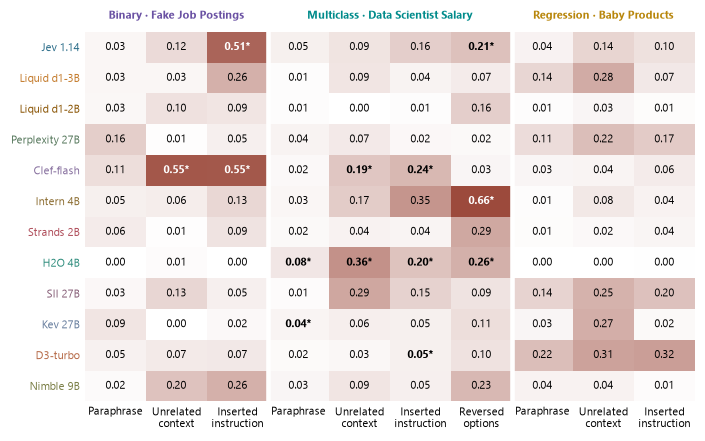

In [2]:
report_section('2. Historical 0A sensitivity diagnostics')
from src.evaluation.notebook_evidence import prompt_evidence
from src.visualize.research import robustness_matrix_figure
changes, distributions, sources = prompt_evidence()
display_table("Every robustness comparison", changes.drop(columns=["source"]))
display_json("Dated robustness receipts", sources)
for fig, name, caption in robustness_matrix_figure(changes):
    save(fig, name, caption=caption)
    display_local(fig)
    plt.close(fig)

In [3]:
from src.evaluation.study_reports import equal_dataset_replay, robustness_tables
report_section("3. Controlled changes to the same requests")
effects, coverage = robustness_tables()
display_table("Measured changes from a fresh original", effects)
display_table("Excess change above unchanged replays, with equal weight per dataset", equal_dataset_replay(effects))
display_table("Coverage, including field orders normalized by the model", coverage)
if effects.empty:
    record("No full RQ1B results are present. The 0A diagnostics above describe a different, smaller sample.")

provider,variant,datasets,mean_excess_tv


## Complete report

In [4]:
finish_report(NOTEBOOK, save.summary() + "\nOnly saved evidence was analysed; no inference, model training or live VSC changes were performed.")

exp02_robustness

1. Scope, provenance and saved evidence


Notebook execution identity
{
  "code_sha256": "6593d29f281dcfc0d9eccf63a245c85c37280db4fed37cd9119be97f14ca2095",
  "git_head": "177427c62a24b29645898e7097943cd650c3b01f",
  "git_dirty": true,
  "tfm_library_pin": "1e5c8fe2c19d746fe3645c584df0c030bc03a117 dm-library (remotes/origin/HEAD)\n 60dffcdab88f20116fe0b17ac5aedfeb96aaa345 tfm-library (remotes/origin/HEAD)\n 211bc65a6155572fef808f2e7bd305c9395a441c vsc-library (heads/main-6-g211bc65)",
  "environment": {
    "python": "3.12.10",
    "numpy": "2.5.4",
    "pandas": "2.3.3",
    "PyYAML": "6.0.3",
    "matplotlib": "3.11.2",
    "pyarrow": "25.0.1"
  }
}


2. Historical 0A sensitivity diagnostics


Every robustness comparison
   provider                                                    source_sha256                                                     probe  total_variation_from_base  same_top_option  maximum_probability_change  expected_direction_change                